In [1]:
# Final Exam Score Prediction

In [2]:
# Step 1: Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [4]:
# Step 2: Load dataset

In [5]:
df = pd.read_csv("edtech_regression_dataset.csv")

df.head()

,study_hours,attendance,quiz_score,final_score
0,4.861241,66.787390,73.925097,102.326773
1,7.867286,57.249407,9.283458,118.735663
2,4.930715,53.663533,31.008742,97.828323
3,5.973968,59.134309,99.558801,125.076944
4,6.887983,61.178486,61.428487,123.053748


In [6]:
# Step 3: Explore the dataset

In [7]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  10000 non-null  float64
 1   attendance   10000 non-null  float64
 2   quiz_score   10000 non-null  float64
 3   final_score  10000 non-null  float64
dtypes: float64(4)
memory usage: 312.6 KB

Statistical Summary:
        study_hours    attendance    quiz_score   final_score
count  10000.000000  10000.000000  10000.000000  10000.000000
mean       4.986748     74.889255     50.374571    102.367783
std        2.011061     14.384455     29.020628     23.711740
min       -2.211836     50.005648      0.014798     14.571985
25%        3.614358     62.433670     25.529728     86.336130
50%        4.982182     74.751805     50.306719    102.607591
75%        6.358791     87.439232     75.627213    118.460803
max       13.038838     99.997412

In [8]:
# Step 4: Exploratory Data Analysis (EDA)

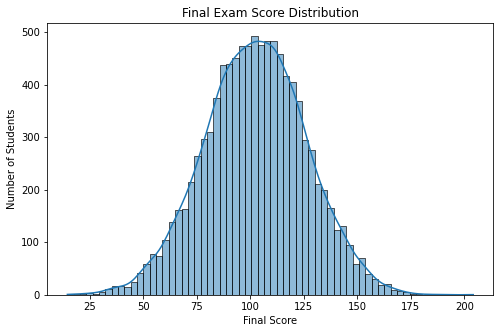

In [10]:
# A. Final score distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["final_score"], kde=True)

plt.title("Final Exam Score Distribution")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()

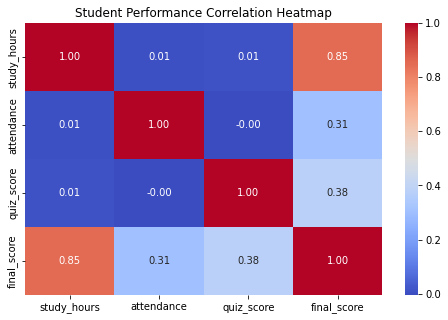

In [11]:
# B. Correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")

plt.show()

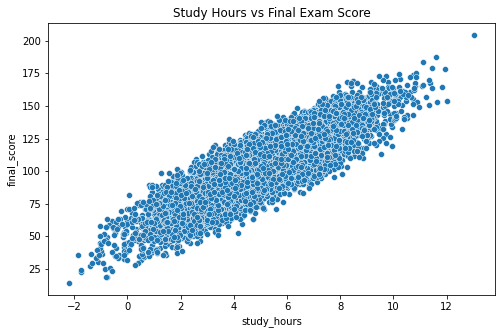

In [12]:
# C. Study hours vs final score
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="study_hours",
    y="final_score"
)

plt.title("Study Hours vs Final Exam Score")
plt.show()

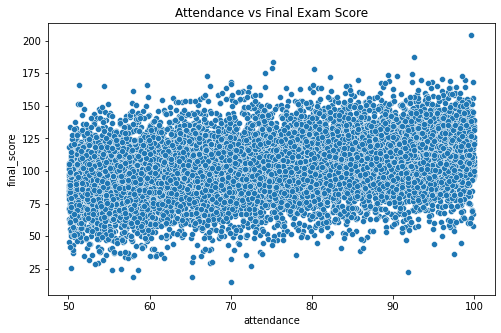

In [13]:
# D. Attendance vs final score
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="attendance",
    y="final_score"
)

plt.title("Attendance vs Final Exam Score")
plt.show()

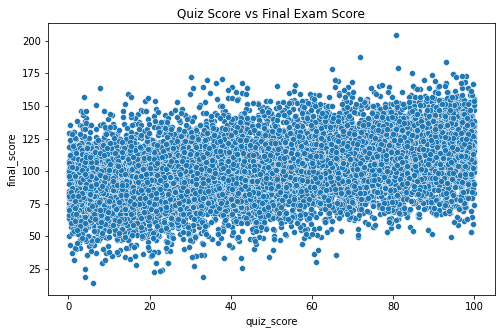

In [14]:
# E. Quiz score vs final score
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="quiz_score",
    y="final_score"
)

plt.title("Quiz Score vs Final Exam Score")
plt.show()

In [15]:
# Step 5: Define independent and dependent variables

In [16]:
X = df[
    [
        "study_hours",
        "attendance",
        "quiz_score"
    ]
]

y = df["final_score"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   study_hours  attendance  quiz_score
0     4.861241   66.787390   73.925097
1     7.867286   57.249407    9.283458
2     4.930715   53.663533   31.008742
3     5.973968   59.134309   99.558801
4     6.887983   61.178486   61.428487

Target:
0    102.326773
1    118.735663
2     97.828323
3    125.076944
4    123.053748
Name: final_score, dtype: float64


In [17]:
# Step 6: Split the dataset

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 3)
Testing Data: (2000, 3)


In [19]:
# Step 7: Build and train Linear Regression

In [20]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [21]:
# Step 8: Make predictions

In [22]:
y_pred = model.predict(X_test)

print("Actual Final Scores:")
print(y_test.head(10).values)

print("\nPredicted Final Scores:")
print(y_pred[:10])

Actual Final Scores:
[ 65.6026478  141.98229238  94.76239214  88.38613897  73.12042355
 118.81497471 102.49073059 128.32209066  72.32389875 120.32599637]

Predicted Final Scores:
[ 71.32953589 146.05287531  96.16550585  83.56116603  73.38695673
 122.68182716 106.0775158  128.88016943  61.57317528 120.68754619]


In [23]:
# Step 9: Evaluate the model

In [24]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 4.021911513350543
MSE: 25.534294975174635
RMSE: 5.053147036765766
R2 Score: 0.9531398355545345


In [25]:
# Step 10: Visualize actual vs predicted scores

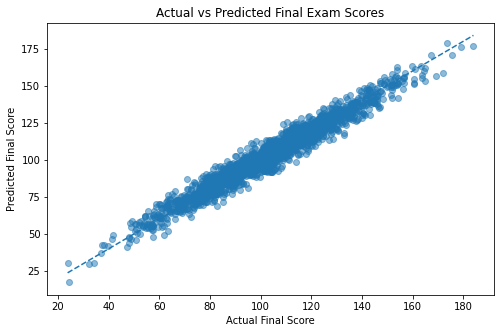

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")

plt.title("Actual vs Predicted Final Exam Scores")

plt.show()

In [27]:
# Step 11: Predict the final score for a new student

In [28]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance": [85],
    "quiz_score": [78]
})

predicted_score = model.predict(new_student)

print(
    "Predicted Final Exam Score:",
    round(predicted_score[0], 2)
)

Predicted Final Exam Score: 125.91


In [29]:
# Step 12: Display feature coefficients

In [30]:
regressor = model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})

print(coefficients)

print("\nIntercept:", regressor.intercept_)

       Feature  Coefficient
0  study_hours    20.176243
1   attendance     7.194777
2   quiz_score     8.788657

Intercept: 102.18892896310572
